# 02 Exploratory Data Analysis

Explore customer characteristics and relationships with the churn target.

Add the executed analysis, outputs, and findings for this stage below.

TELCO CUSTOMER CHURN CLASSIFICATION
STAGE 2: EXPLORATORY DATA ANALYSIS

Dataset successfully loaded!
Dataset shape: (7043, 21)

[1] CHURN DISTRIBUTION

Jumlah pelanggan:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Persentase pelanggan:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


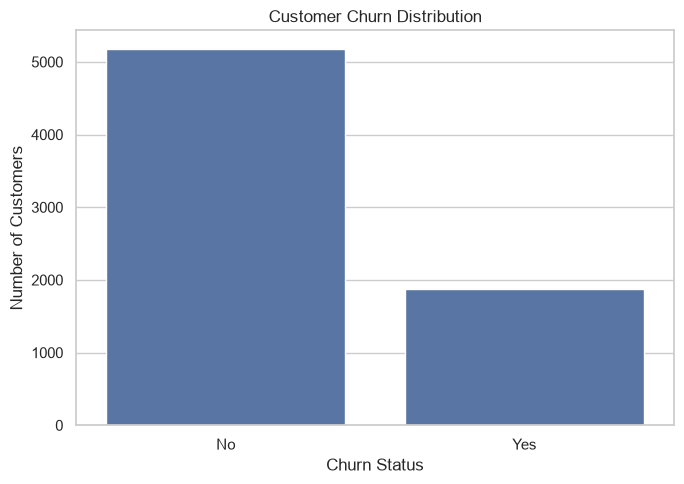


[2] NUMERICAL FEATURES DISTRIBUTION
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80


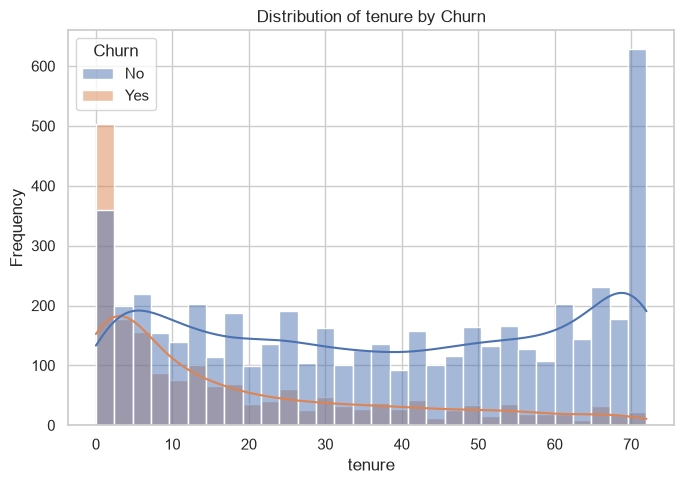

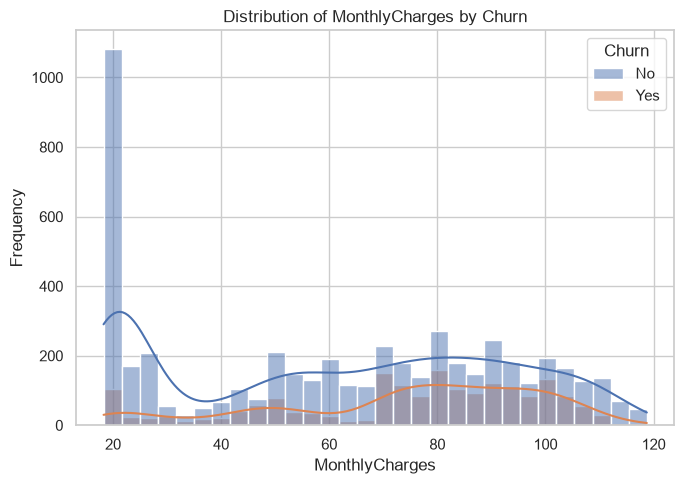

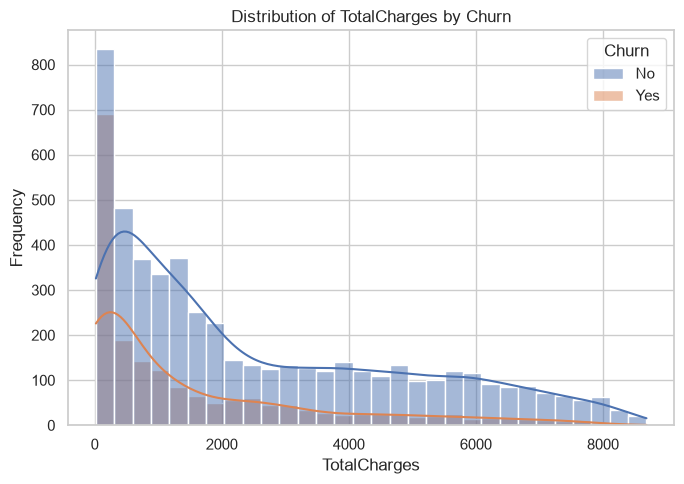


[3] CHURN BASED ON CONTRACT TYPE
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


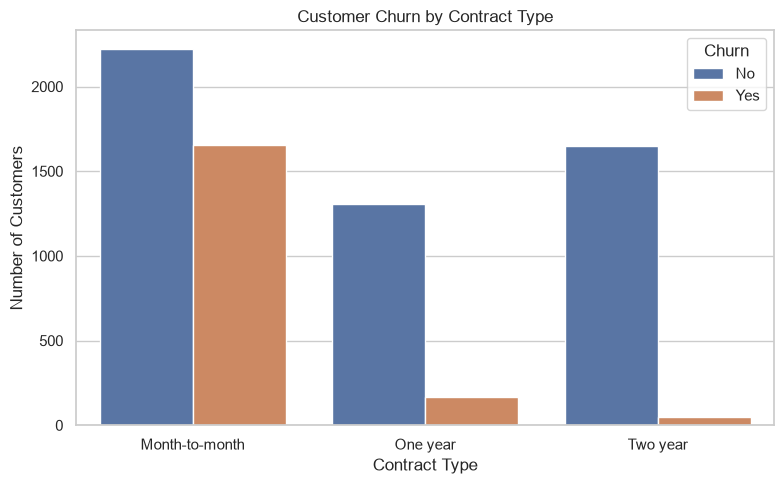


[4] CHURN BASED ON INTERNET SERVICE
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


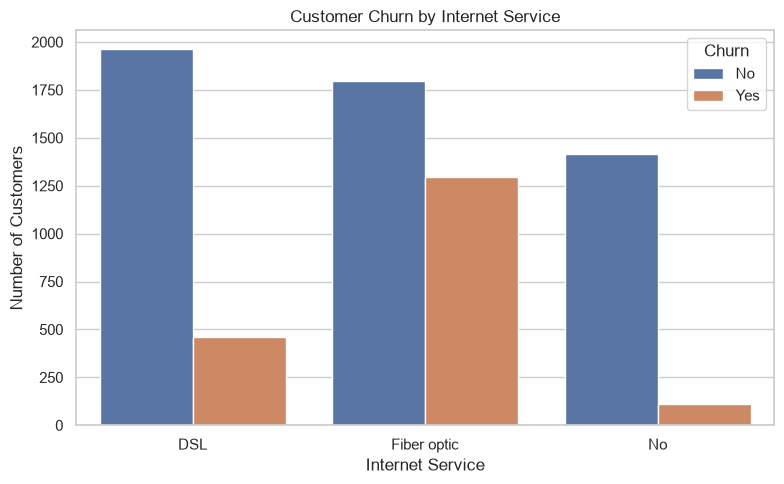


[5] CHURN BASED ON PAYMENT METHOD
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


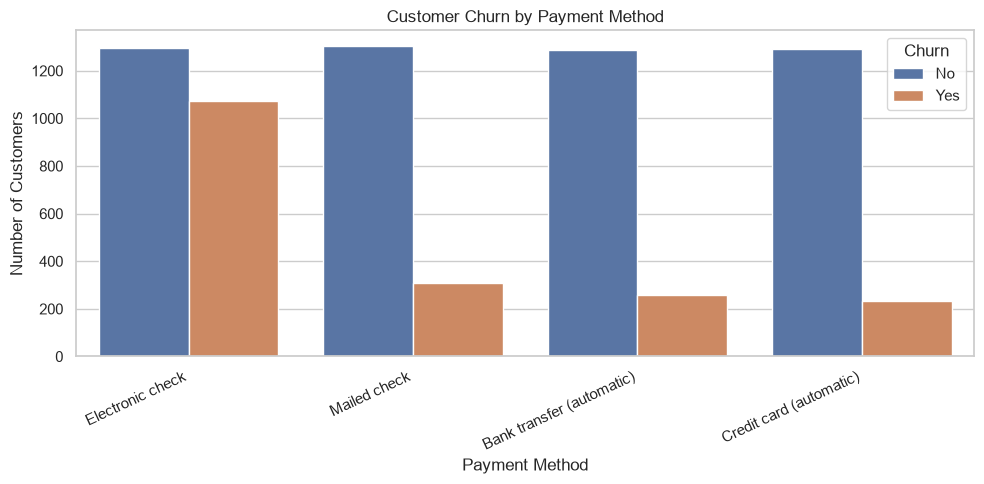


[6] NUMERICAL CORRELATION
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


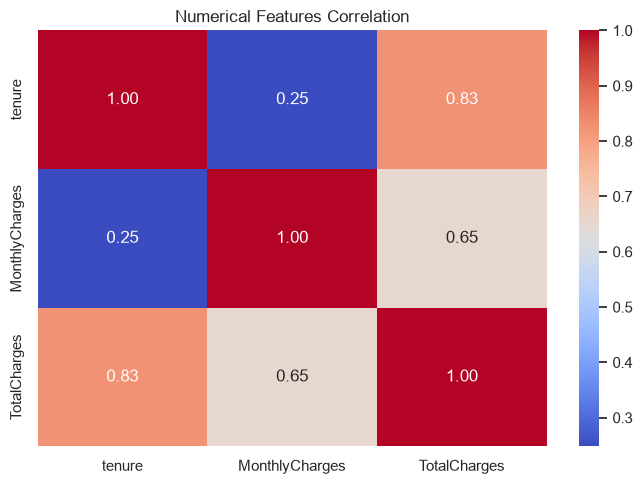


[7] EDA SUMMARY
Total Customers: 7043
Churn Customers: 1869
Non-Churn Customers: 5174
Churn Rate: 26.54%

EDA completed successfully!
Visualizations saved in: ..\images


In [1]:

# ============================================================
# TELCO CUSTOMER CHURN CLASSIFICATION
# STAGE 2: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("=" * 60)
print("TELCO CUSTOMER CHURN CLASSIFICATION")
print("STAGE 2: EXPLORATORY DATA ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

data_path = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(data_path)

# Membuat folder images jika belum tersedia
image_dir = Path("../images")
image_dir.mkdir(parents=True, exist_ok=True)

print("\nDataset successfully loaded!")
print(f"Dataset shape: {df.shape}")

# ------------------------------------------------------------
# 2. TARGET VARIABLE DISTRIBUTION
# ------------------------------------------------------------

print("\n[1] CHURN DISTRIBUTION")

churn_counts = df["Churn"].value_counts()
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("\nJumlah pelanggan:")
print(churn_counts)

print("\nPersentase pelanggan:")
print(churn_percentages.round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(image_dir / "01_churn_distribution.png")
plt.show()

# ------------------------------------------------------------
# 3. NUMERICAL FEATURES DISTRIBUTION
# ------------------------------------------------------------

print("\n[2] NUMERICAL FEATURES DISTRIBUTION")

# TotalCharges dikonversi untuk analisis jika masih bertipe object
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print(df[numerical_cols].describe().round(2))

for col in numerical_cols:
    plt.figure(figsize=(7, 5))
    sns.histplot(data=df, x=col, hue="Churn",
                 kde=True, bins=30)
    plt.title(f"Distribution of {col} by Churn")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(image_dir / f"02_{col}_distribution.png")
    plt.show()

# ------------------------------------------------------------
# 4. CHURN BASED ON CONTRACT TYPE
# ------------------------------------------------------------

print("\n[3] CHURN BASED ON CONTRACT TYPE")

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(image_dir / "03_churn_by_contract.png")
plt.show()

# ------------------------------------------------------------
# 5. CHURN BASED ON INTERNET SERVICE
# ------------------------------------------------------------

print("\n[4] CHURN BASED ON INTERNET SERVICE")

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(image_dir / "04_churn_by_internet_service.png")
plt.show()

# ------------------------------------------------------------
# 6. CHURN BASED ON PAYMENT METHOD
# ------------------------------------------------------------

print("\n[5] CHURN BASED ON PAYMENT METHOD")

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(image_dir / "05_churn_by_payment_method.png")
plt.show()

# ------------------------------------------------------------
# 7. CORRELATION ANALYSIS
# ------------------------------------------------------------

print("\n[6] NUMERICAL CORRELATION")

correlation = df[numerical_cols].corr()

print(correlation.round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Numerical Features Correlation")
plt.tight_layout()
plt.savefig(image_dir / "06_correlation_heatmap.png")
plt.show()

# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n[7] EDA SUMMARY")

print(f"Total Customers: {len(df)}")
print(f"Churn Customers: {(df['Churn'] == 'Yes').sum()}")
print(f"Non-Churn Customers: {(df['Churn'] == 'No').sum()}")
print(f"Churn Rate: {(df['Churn'] == 'Yes').mean() * 100:.2f}%")

print("\nEDA completed successfully!")
print(f"Visualizations saved in: {image_dir}")
